In [4]:
import pandas as pd
import os

print(os.path.expanduser("~/Downloads"))

C:\Users\Abhishek/Downloads


In [5]:
%pip install xlrd

Note: you may need to restart the kernel to use updated packages.


In [7]:
import pandas as pd
from pathlib import Path

downloads = Path.home() / "Downloads"

files = list(downloads.glob("sample_-_superstore.*"))
print(files)

[WindowsPath('C:/Users/Abhishek/Downloads/sample_-_superstore.xls')]


In [8]:
df = pd.read_excel(files[0])

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [9]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (10194, 21)

Column Names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing Values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country/Region    0
City              0
State/Province    0
Postal Code       0
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
dtype: int64


In [10]:

# Check duplicate rows
print("Duplicate Rows:", df.duplicated().sum())

# Descriptive statistics
print("\nStatistical Summary:")
display(df.describe())

# Mean, Median, Mode and Standard Deviation
numerical_cols = df.select_dtypes(include="number")

stats = pd.DataFrame({
    "Mean": numerical_cols.mean(),
    "Median": numerical_cols.median(),
    "Mode": numerical_cols.mode().iloc[0],
    "Std Deviation": numerical_cols.std()
})

display(stats)


Duplicate Rows: 0

Statistical Summary:


,Row ID,Order Date,Ship Date,Sales,Quantity,Discount,Profit
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-04-29 11:48:25.002943,2025-05-03 10:52:45.626839,228.225854,3.791838,0.155385,28.673417
min,1.000000,2023-01-03 00:00:00,2023-01-07 00:00:00,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,2024-05-14 00:00:00,2024-05-19 00:00:00,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,2025-06-25 00:00:00,2025-06-28 00:00:00,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,2026-05-14 00:00:00,2026-05-18 00:00:00,209.500000,5.000000,0.200000,29.297925
max,10194.000000,2026-12-30 00:00:00,2027-01-05 00:00:00,22638.480000,14.000000,0.800000,8399.976000
std,2942.898656,NaN,NaN,619.906839,2.228317,0.206249,232.465115


,Mean,Median,Mode,Std Deviation
Row ID,5097.500000,5097.50,1.00,2942.898656
Sales,228.225854,53.91,12.96,619.906839
Quantity,3.791838,3.00,2.00,2.228317
Discount,0.155385,0.20,0.00,0.206249
Profit,28.673417,8.69,0.00,232.465115


In [11]:

# Convert dates to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

# Verify data types
print(df[["Order Date", "Ship Date"]].dtypes)


Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [12]:

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)


Total Sales: 2326534.35
Total Profit: 292296.81
Total Orders: 5111
Total Customers: 804


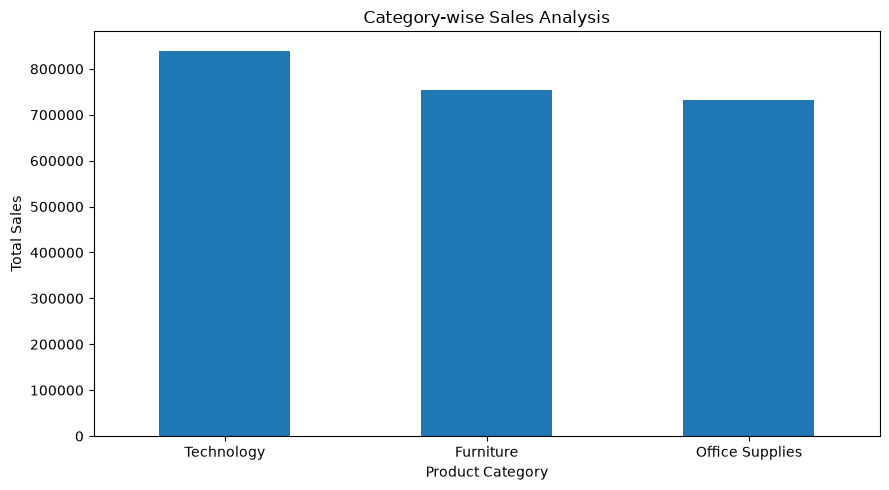

In [13]:

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

category_sales.plot(kind="bar")

plt.title("Category-wise Sales Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


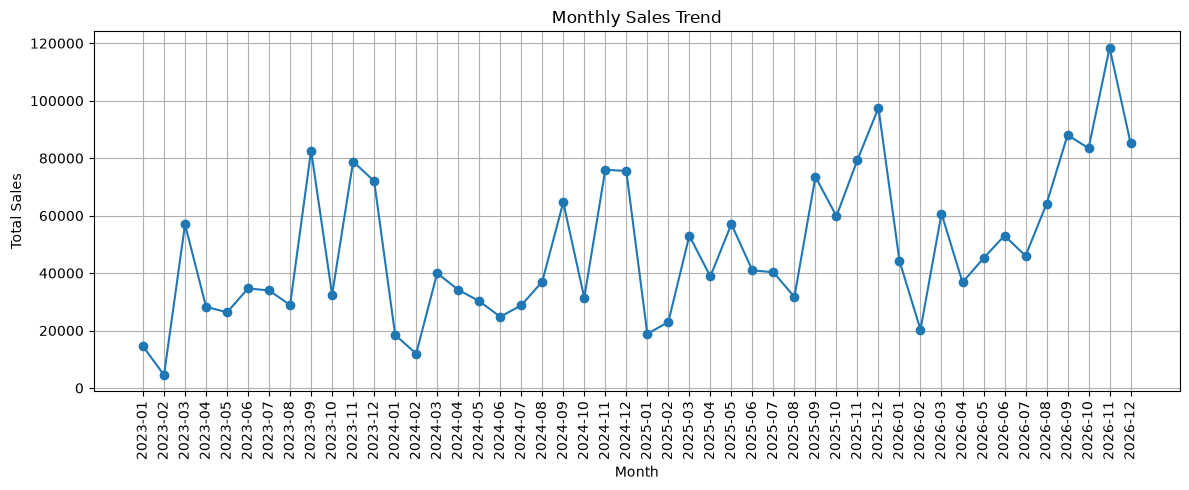

In [14]:

# Convert Order Date to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Calculate monthly sales
monthly_sales = (
    df.groupby(df["Order Date"].dt.to_period("M"))["Sales"]
    .sum()
)

# Convert month labels
monthly_sales.index = monthly_sales.index.astype(str)

# Plot monthly sales
plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values,
         marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()


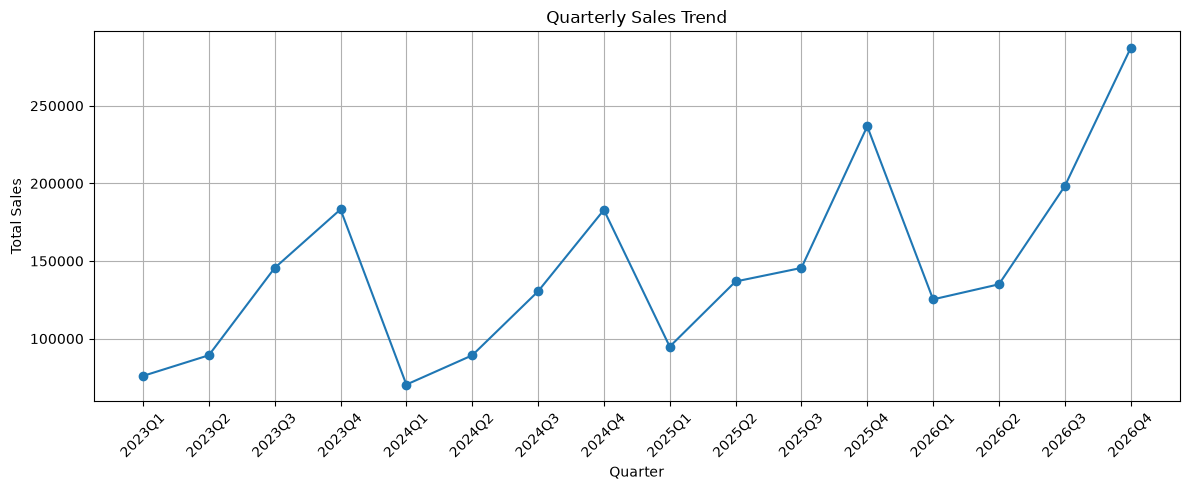

In [15]:

quarterly_sales = (
    df.groupby(df["Order Date"].dt.to_period("Q"))["Sales"]
    .sum()
)

quarterly_sales.index = quarterly_sales.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(quarterly_sales.index,
         quarterly_sales.values,
         marker="o")

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


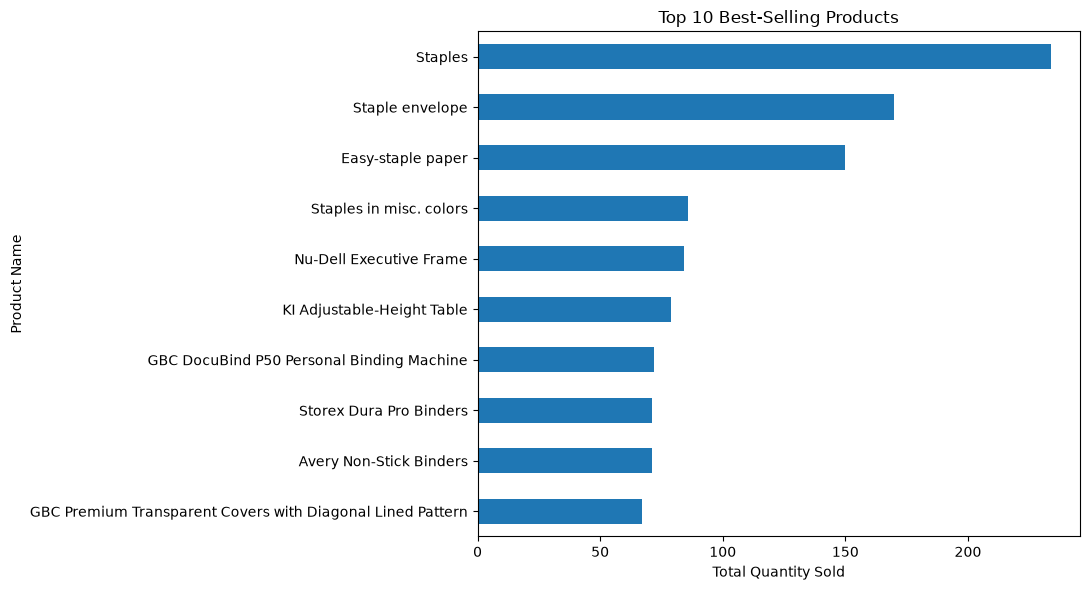

In [16]:

top_products = (
    df.groupby("Product Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 6))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()


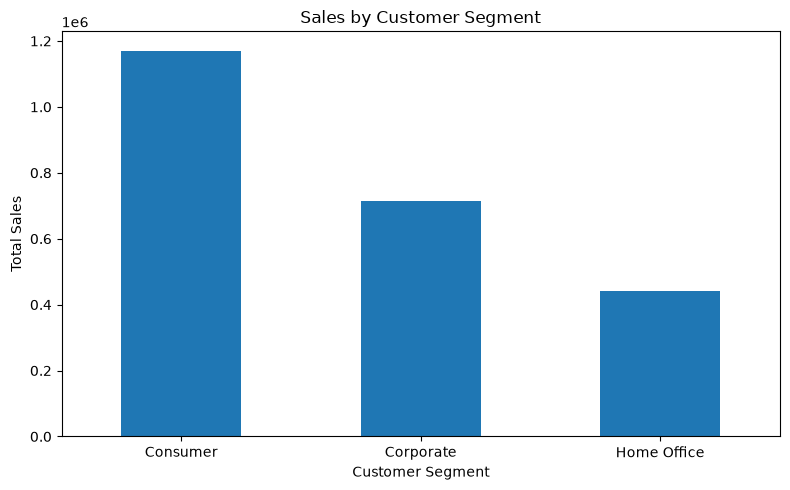

In [17]:

segment_sales = (
    df.groupby("Segment")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
segment_sales.plot(kind="bar")

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


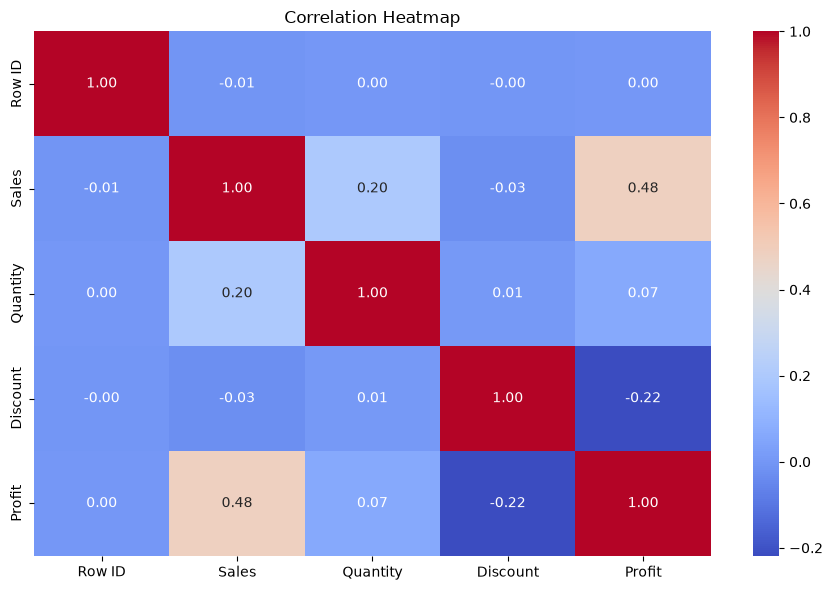

In [18]:

numerical_data = df.select_dtypes(include="number")

plt.figure(figsize=(9, 6))

sns.heatmap(
    numerical_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()



## Correlation Analysis — Key Findings

1. Sales and Profit have a moderate positive
   correlation of 0.48.

2. Discount and Profit have a weak negative
   correlation of -0.22.

3. Quantity and Profit have a very weak
   positive correlation of 0.07.

### Business Recommendations

1. Review discount strategies to protect
   profit margins.

2. Focus on products that generate both
   strong sales and profitability.

3. Monitor sales and profit together rather
   than evaluating revenue alone.



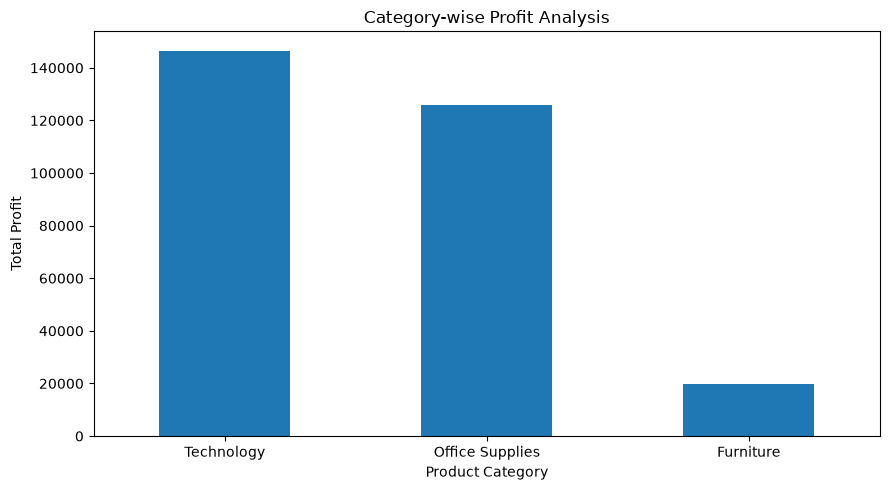

Category
Technology         146543.3756
Office Supplies    126023.4434
Furniture           19729.9956
Name: Profit, dtype: float64


In [20]:

category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))

category_profit.plot(kind="bar")

plt.title("Category-wise Profit Analysis")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print(category_profit)



## Category-wise Profit Analysis

### Key Findings

1. Technology generates the highest profit
   of 146,543.38.

2. Office Supplies generates a profit
   of 126,023.44.

3. Furniture generates the lowest profit
   of 19,729.99.

### Business Recommendations

1. Prioritize profitable Technology products.

2. Review Furniture discounts, costs and
   low-margin products.

3. Maintain strong-performing Office Supplies
   products while monitoring profitability.


In [21]:

category_summary = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

category_summary["Profit_Margin_%"] = (
    category_summary["Total_Profit"] /
    category_summary["Total_Sales"] * 100
)

display(category_summary.round(2))


,Total_Sales,Total_Profit,Profit_Margin_%
Category,,,
Furniture,754747.76,19730.00,2.61
Office Supplies,731893.31,126023.44,17.22
Technology,839893.28,146543.38,17.45



## Profit Margin Analysis

### Key Findings

1. Technology has the highest profit margin
   at 17.45%.

2. Office Supplies has a strong profit margin
   of 17.22%.

3. Furniture has the lowest profit margin
   at 2.61%, despite generating substantial sales.

### Business Recommendations

1. Review discounts and costs in the
   Furniture category.

2. Prioritize high-margin Technology products
   while monitoring customer demand.

3. Maintain the profitability of Office
   Supplies through pricing and cost control.


In [22]:

from pathlib import Path
import pandas as pd

downloads = Path.home() / "Downloads"

# Find possible E-Commerce CSV files
files = list(downloads.rglob(
    "*ecommerce*customer*behavior*.csv"
))

print(files)


[WindowsPath('C:/Users/Abhishek/Downloads/archive/ecommerce_customer_behavior_dataset.csv'), WindowsPath('C:/Users/Abhishek/Downloads/archive/ecommerce_customer_behavior_dataset_v2.csv')]


In [23]:

if files:
    ecommerce_df = pd.read_csv(files[0])
    print(ecommerce_df.columns.tolist())
    display(ecommerce_df.head())
else:
    print("CSV not found. Check your ZIP file.")


['Order_ID', 'Customer_ID', 'Date', 'Age', 'Gender', 'City', 'Product_Category', 'Unit_Price', 'Quantity', 'Discount_Amount', 'Total_Amount', 'Payment_Method', 'Device_Type', 'Session_Duration_Minutes', 'Pages_Viewed', 'Is_Returning_Customer', 'Delivery_Time_Days', 'Customer_Rating']


,Order_ID,Customer_ID,Date,Age,Gender,City,Product_Category,Unit_Price,Quantity,Discount_Amount,Total_Amount,Payment_Method,Device_Type,Session_Duration_Minutes,Pages_Viewed,Is_Returning_Customer,Delivery_Time_Days,Customer_Rating
0,ORD_001337,CUST_01337,2023-01-01,27,Female,Bursa,Toys,54.28,1,0.00,54.28,Debit Card,Mobile,4,14,True,8,5
1,ORD_004885,CUST_04885,2023-01-01,42,Male,Konya,Toys,244.90,1,0.00,244.90,Credit Card,Mobile,11,3,True,3,3
2,ORD_004507,CUST_04507,2023-01-01,43,Female,Ankara,Food,48.15,5,0.00,240.75,Credit Card,Mobile,7,8,True,5,2
3,ORD_000645,CUST_00645,2023-01-01,32,Male,Istanbul,Electronics,804.06,1,229.28,574.78,Credit Card,Mobile,8,10,False,1,4
4,ORD_000690,CUST_00690,2023-01-01,40,Female,Istanbul,Sports,755.61,5,0.00,3778.05,Cash on Delivery,Desktop,21,10,True,7,4
